# E-Commerce Sales: Data Cleaning, EDA & Dashboard

**Goal:** Take a raw, messy e-commerce sales dataset and turn it into clean, trustworthy data with a visual report of key business insights.

**Workflow**
1. Load & inspect raw data
2. Identify data quality issues (missing values, duplicates, outliers, inconsistent formatting)
3. Clean the data with documented, justified decisions
4. Exploratory Data Analysis (EDA)
5. Dashboard-style visual summary of key findings

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

df = pd.read_csv("raw_ecommerce_sales.csv")
print(f"Shape: {df.shape}")
df.head()


Shape: (2565, 12)


,OrderID,OrderDate,Category,ProductPrice,Quantity,DiscountPercent,CustomerCity,CustomerAge,CustomerGender,PaymentMode,Rating,DeliveryDays
0,100158,13-01-2024,ELECTRONICS,767.37,1,0.0,mumbai,21.0,Other,Net Banking,3.6,3.0
1,100112,"August 25, 2024",beauty,849.95,3,0.0,ahmedabad,NaN,Female,Cash on Delivery,3.3,6.0
2,100945,2024/04/21,Electronics,716.79,1,0.0,Calcutta,40.0,Male,UPI,3.5,1.0
3,101958,"June 13, 2023",Beauty,1341.68,1,0.0,hyderabad,39.0,Female,Cash on Delivery,4.0,4.0
4,100349,2024/09/24,sports,804.39,4,10.0,Pune,26.0,Female,Net Banking,5.0,5.0


## 1. Initial Inspection

Before touching anything, get a full picture of the dataset: types, ranges, missingness, and obvious anomalies.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2565 entries, 0 to 2564
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          2565 non-null   int64  
 1   OrderDate        2565 non-null   str    
 2   Category         2565 non-null   str    
 3   ProductPrice     2565 non-null   float64
 4   Quantity         2565 non-null   int64  
 5   DiscountPercent  2486 non-null   float64
 6   CustomerCity     2462 non-null   str    
 7   CustomerAge      2440 non-null   float64
 8   CustomerGender   2565 non-null   str    
 9   PaymentMode      2539 non-null   str    
 10  Rating           2353 non-null   float64
 11  DeliveryDays     2514 non-null   float64
dtypes: float64(5), int64(2), str(5)
memory usage: 240.6 KB


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OrderID,2565.0,NaN,NaN,NaN,101249.502144,720.893705,100000.0,100625.0,101249.0,101873.0,102499.0
OrderDate,2565,1788,2023-05-24,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,2565,21,Toys,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProductPrice,2565.0,NaN,NaN,NaN,1870.911889,3619.947521,-5004.19,755.8,1315.98,2168.07,79447.760384
Quantity,2565.0,NaN,NaN,NaN,1.468226,0.876247,1.0,1.0,1.0,2.0,5.0
DiscountPercent,2486.0,NaN,NaN,NaN,7.825825,8.064718,0.0,0.0,5.0,15.0,25.0
CustomerCity,2462,22,Chennai,170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerAge,2440.0,NaN,NaN,NaN,32.235656,10.521333,-5.0,25.0,32.0,39.0,130.0
CustomerGender,2565,4,Other,865,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMode,2539,5,Net Banking,565,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_count", ascending=False)


,missing_count,missing_pct
Rating,212,8.27
CustomerAge,125,4.87
CustomerCity,103,4.02
DiscountPercent,79,3.08
DeliveryDays,51,1.99
PaymentMode,26,1.01


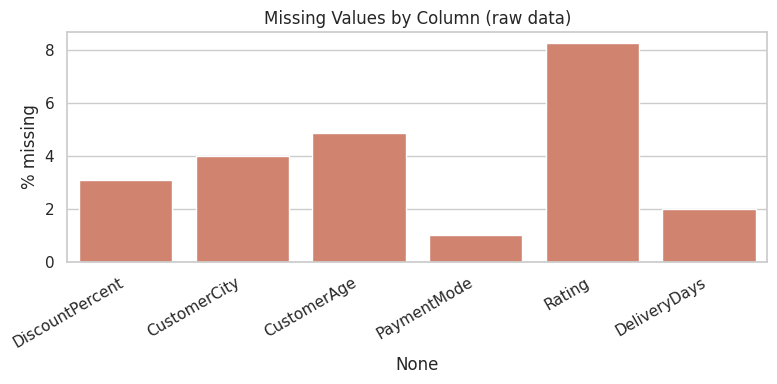

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing_summary[missing_summary.missing_count>0].index,
            y=missing_summary[missing_summary.missing_count>0]["missing_pct"], ax=ax, color="#e07a5f")
ax.set_ylabel("% missing")
ax.set_title("Missing Values by Column (raw data)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


**Observations from initial inspection:**
- `Category` and `CustomerCity` have inconsistent casing/spelling (`ELECTRONICS`, `electronics`, `Bangalore` vs `Bengaluru`, etc.)
- `OrderDate` is stored as text in multiple formats (`13-01-2024`, `August 25, 2024`, `2024/04/21`...)
- `Rating`, `CustomerAge`, `CustomerCity`, `DiscountPercent`, `DeliveryDays` contain missing values
- `PaymentMode` and `CustomerGender` have blank/whitespace-only strings instead of proper NaNs
- Numeric columns (`ProductPrice`, `CustomerAge`, `DeliveryDays`) likely contain outliers/data-entry errors
- There may be exact and near-duplicate rows


## 2. Handling Duplicates

In [6]:
exact_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {exact_dupes}")

# Also check duplicates on OrderID (should be unique - a real primary key)
id_dupes = df.duplicated(subset=["OrderID"]).sum()
print(f"Duplicate OrderIDs: {id_dupes}")


Exact duplicate rows: 55
Duplicate OrderIDs: 65


In [7]:
# Drop exact duplicate rows
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} exact duplicate rows -> {len(df)} rows remain")

# For duplicate OrderIDs (same order recorded twice with minor differences), keep first occurrence
before = len(df)
df = df.drop_duplicates(subset=["OrderID"], keep="first")
print(f"Removed {before - len(df)} rows with duplicate OrderID -> {len(df)} rows remain")


Removed 55 exact duplicate rows -> 2510 rows remain
Removed 10 rows with duplicate OrderID -> 2500 rows remain


## 3. Standardizing Text & Categorical Fields

Fixing casing, stray whitespace, and inconsistent naming so the same real-world value isn't split across multiple labels.

In [8]:
# Replace whitespace-only strings with proper NaN first
df = df.replace(r'^\s*$', np.nan, regex=True)

# Standardize Category: strip + title case + fix "Home and Kitchen"
df["Category"] = df["Category"].astype(str).str.strip().str.lower()
df["Category"] = df["Category"].replace({"home and kitchen": "home & kitchen"})
df["Category"] = df["Category"].str.title().str.replace("Home & Kitchen".title(), "Home & Kitchen")
df["Category"] = df["Category"].replace({"nan": np.nan})

# Standardize CustomerCity: strip + title case + fix known aliases
df["CustomerCity"] = df["CustomerCity"].astype(str).str.strip().str.title()
df["CustomerCity"] = df["CustomerCity"].replace({
    "Bangalore": "Bengaluru",
    "Calcutta": "Kolkata",
    "New Delhi": "Delhi",
    "Nan": np.nan
})

# Standardize CustomerGender
df["CustomerGender"] = df["CustomerGender"].astype(str).str.strip().str.title()
df["CustomerGender"] = df["CustomerGender"].replace({"Nan": np.nan})

print(df["Category"].unique())
print(df["CustomerCity"].unique())
print(df["CustomerGender"].unique())


<StringArray>
[   'Electronics',         'Beauty',         'Sports',           'Toys',
          'Books',       'Clothing', 'Home & Kitchen']
Length: 7, dtype: str
<StringArray>
[   'Mumbai', 'Ahmedabad',   'Kolkata', 'Hyderabad',      'Pune', 'Bengaluru',
   'Chennai',     'Delhi',         nan]
Length: 9, dtype: str
<StringArray>
['Other', 'Female', 'Male', nan]
Length: 4, dtype: str


## 4. Parsing Inconsistent Date Formats

`OrderDate` mixes several formats. `pandas.to_datetime` with `format="mixed"` infers the format per-row.

In [9]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"], format="mixed", dayfirst=True, errors="coerce")
print("Unparseable dates:", df["OrderDate"].isna().sum())
print(df["OrderDate"].min(), "to", df["OrderDate"].max())

df["OrderMonth"] = df["OrderDate"].dt.to_period("M").astype(str)


Unparseable dates: 0
2023-01-01 00:00:00 to 2024-12-31 00:00:00


## 5. Detecting & Handling Outliers

Using boxplots + the IQR method on the key numeric columns. Decisions are made per-column based on what's a plausible real-world value vs. a data-entry error.

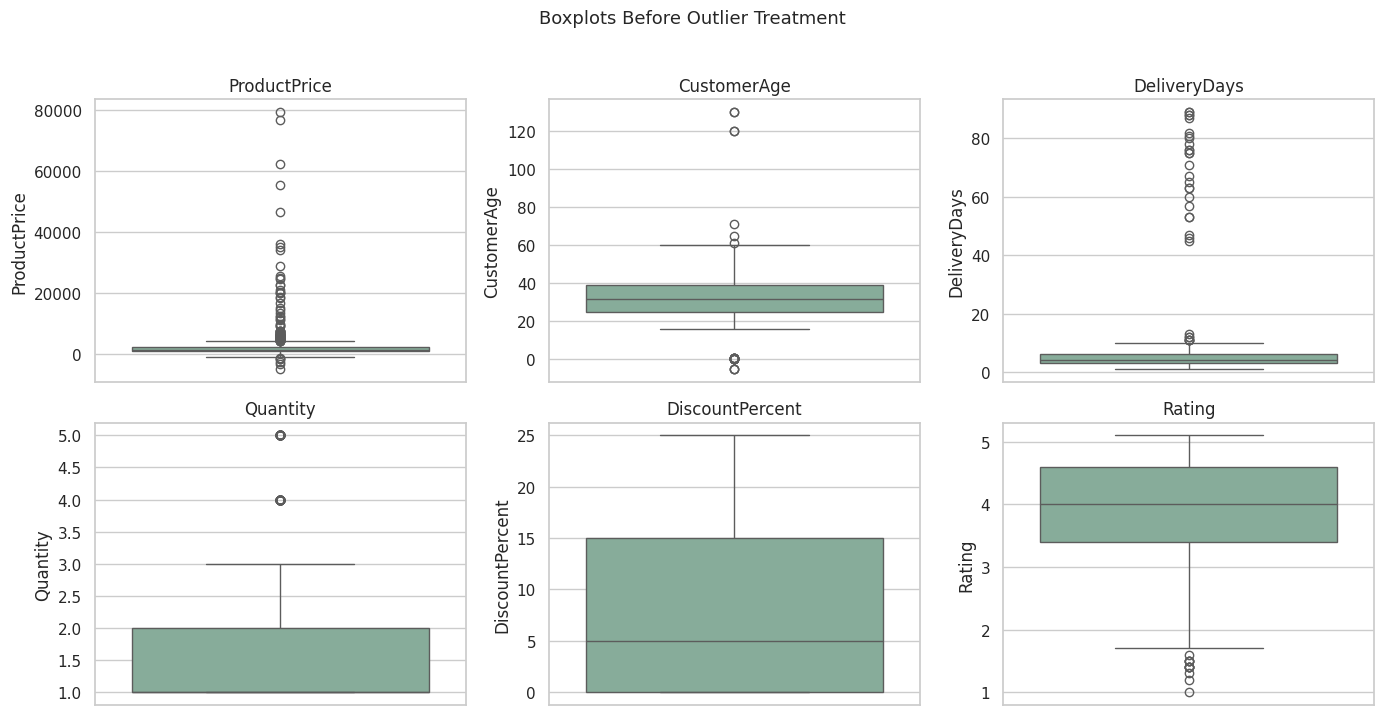

In [10]:
numeric_cols = ["ProductPrice", "CustomerAge", "DeliveryDays", "Quantity", "DiscountPercent", "Rating"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#81b29a")
    ax.set_title(col)
plt.suptitle("Boxplots Before Outlier Treatment", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()


In [11]:
# --- ProductPrice: negative values are data-entry errors -> take absolute value ---
neg_price_count = (df["ProductPrice"] < 0).sum()
df["ProductPrice"] = df["ProductPrice"].abs()
print(f"Fixed {neg_price_count} negative prices by taking absolute value")

# --- ProductPrice: cap extreme high outliers using IQR (winsorize rather than drop, to preserve sample size) ---
Q1, Q3 = df["ProductPrice"].quantile([0.25, 0.75])
IQR = Q3 - Q1
upper_bound = Q3 + 3 * IQR  # 3x IQR = conservative, only catches extreme cases
price_outliers = (df["ProductPrice"] > upper_bound).sum()
df["ProductPrice"] = df["ProductPrice"].clip(upper=upper_bound)
print(f"Capped {price_outliers} extreme ProductPrice outliers at {upper_bound:.2f}")

# --- CustomerAge: values outside a plausible human range are errors -> set to NaN, then impute ---
implausible_age = (~df["CustomerAge"].between(10, 90)).sum()
df.loc[~df["CustomerAge"].between(10, 90), "CustomerAge"] = np.nan
print(f"Flagged {implausible_age} implausible ages as missing (outside 10-90)")

# --- DeliveryDays: cap unrealistic delivery windows (>30 days is very likely a logging error) ---
delivery_outliers = (df["DeliveryDays"] > 30).sum()
df.loc[df["DeliveryDays"] > 30, "DeliveryDays"] = np.nan
print(f"Flagged {delivery_outliers} DeliveryDays > 30 as missing")


Fixed 12 negative prices by taking absolute value
Capped 43 extreme ProductPrice outliers at 6401.06
Flagged 142 implausible ages as missing (outside 10-90)
Flagged 25 DeliveryDays > 30 as missing


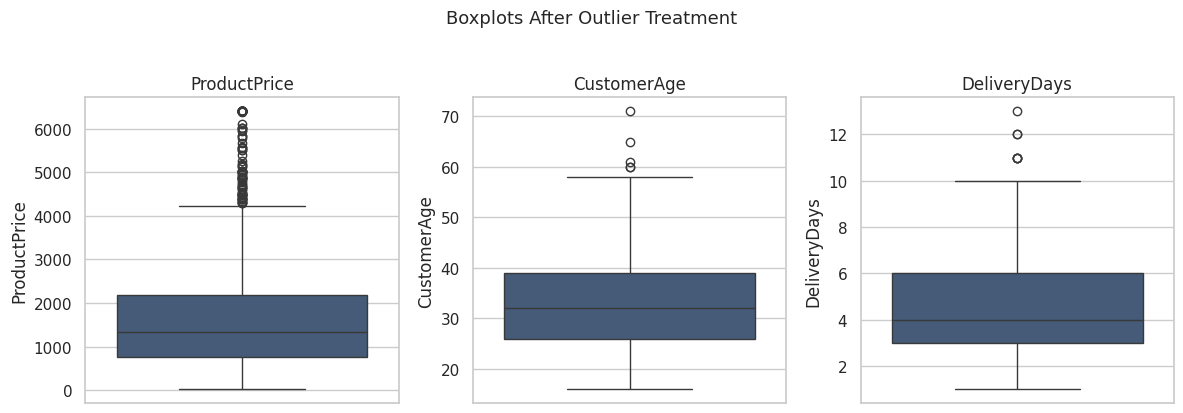

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["ProductPrice", "CustomerAge", "DeliveryDays"]):
    sns.boxplot(y=df[col], ax=ax, color="#3d5a80")
    ax.set_title(col)
plt.suptitle("Boxplots After Outlier Treatment", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()


## 6. Handling Missing Values

Strategy depends on the column:
- **Numeric (Rating, CustomerAge, DiscountPercent, DeliveryDays):** median imputation (robust to remaining skew/outliers)
- **Categorical (CustomerCity, PaymentMode, CustomerGender):** mode imputation, or an explicit "Unknown" label where imputing a guess could mislead


In [13]:
print("Missing values before imputation:\n", df.isna().sum()[df.isna().sum() > 0])


Missing values before imputation:
 DiscountPercent     75
CustomerCity       100
CustomerAge        142
CustomerGender      25
PaymentMode         25
Rating             200
DeliveryDays        75
dtype: int64


In [14]:
# Numeric imputation with median (robust to skew)
for col in ["Rating", "CustomerAge", "DiscountPercent", "DeliveryDays"]:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Categorical: use "Unknown" label instead of guessing, so it stays analyzable but honest
for col in ["CustomerCity", "PaymentMode", "CustomerGender"]:
    df[col] = df[col].fillna("Unknown")

# Rows with unparseable OrderDate: drop, since date drives most of the analysis
before = len(df)
df = df.dropna(subset=["OrderDate"])
print(f"Dropped {before - len(df)} rows with unparseable dates")

print("\nMissing values after cleaning:\n", df.isna().sum().sum(), "total missing values remaining")


Dropped 0 rows with unparseable dates

Missing values after cleaning:
 0 total missing values remaining


In [15]:
# Derived column used throughout the analysis
df["Revenue"] = df["ProductPrice"] * df["Quantity"] * (1 - df["DiscountPercent"] / 100)
df["Revenue"] = df["Revenue"].round(2)

df.to_csv("cleaned_ecommerce_sales.csv", index=False)
print(f"Final cleaned shape: {df.shape}")
df.head()


Final cleaned shape: (2500, 14)


,OrderID,OrderDate,Category,ProductPrice,Quantity,DiscountPercent,CustomerCity,CustomerAge,CustomerGender,PaymentMode,Rating,DeliveryDays,OrderMonth,Revenue
0,100158,2024-01-13,Electronics,767.37,1,0.0,Mumbai,21.0,Other,Net Banking,3.6,3.0,2024-01,767.37
1,100112,2024-08-25,Beauty,849.95,3,0.0,Ahmedabad,32.0,Female,Cash on Delivery,3.3,6.0,2024-08,2549.85
2,100945,2024-04-21,Electronics,716.79,1,0.0,Kolkata,40.0,Male,UPI,3.5,1.0,2024-04,716.79
3,101958,2023-06-13,Beauty,1341.68,1,0.0,Hyderabad,39.0,Female,Cash on Delivery,4.0,4.0,2023-06,1341.68
4,100349,2024-09-24,Sports,804.39,4,10.0,Pune,26.0,Female,Net Banking,5.0,5.0,2024-09,2895.80


## 7. Exploratory Data Analysis

With clean data in hand, explore patterns in sales, customers, and product categories.

In [16]:
print("Revenue summary:")
print(df["Revenue"].describe().round(2))
print(f"\nTotal Revenue: ₹{df['Revenue'].sum():,.0f}")
print(f"Total Orders: {len(df):,}")
print(f"Average Order Value: ₹{df['Revenue'].mean():,.2f}")


Revenue summary:
count     2500.00
mean      2201.06
std       2310.43
min         19.55
25%        839.54
50%       1554.81
75%       2637.97
max      28804.76
Name: Revenue, dtype: float64

Total Revenue: ₹5,502,643
Total Orders: 2,500
Average Order Value: ₹2,201.06


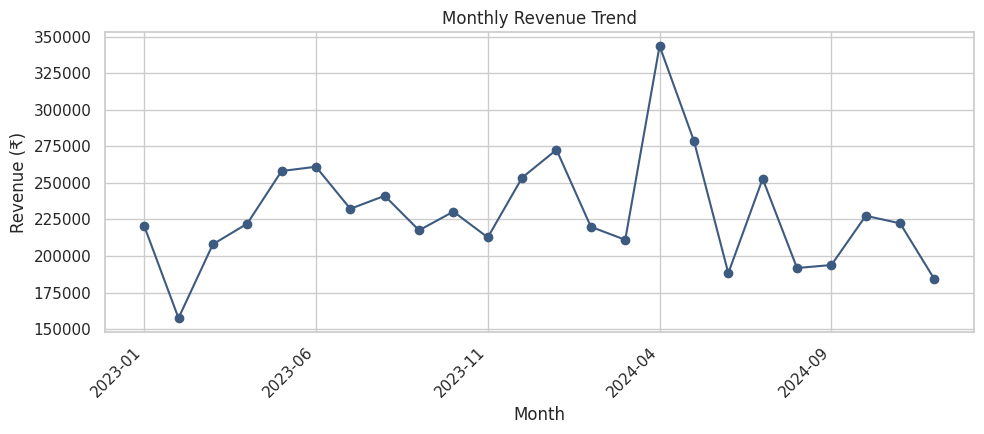

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
monthly = df.groupby("OrderMonth")["Revenue"].sum().sort_index()
monthly.plot(kind="line", marker="o", ax=ax, color="#3d5a80")
ax.set_title("Monthly Revenue Trend")
ax.set_ylabel("Revenue (₹)")
ax.set_xlabel("Month")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


/tmp/ipykernel_596/3849509356.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_revenue.values, y=cat_revenue.index, ax=axes[0], palette="viridis")
/tmp/ipykernel_596/3849509356.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_orders.values, y=cat_orders.index, ax=axes[1], palette="magma")


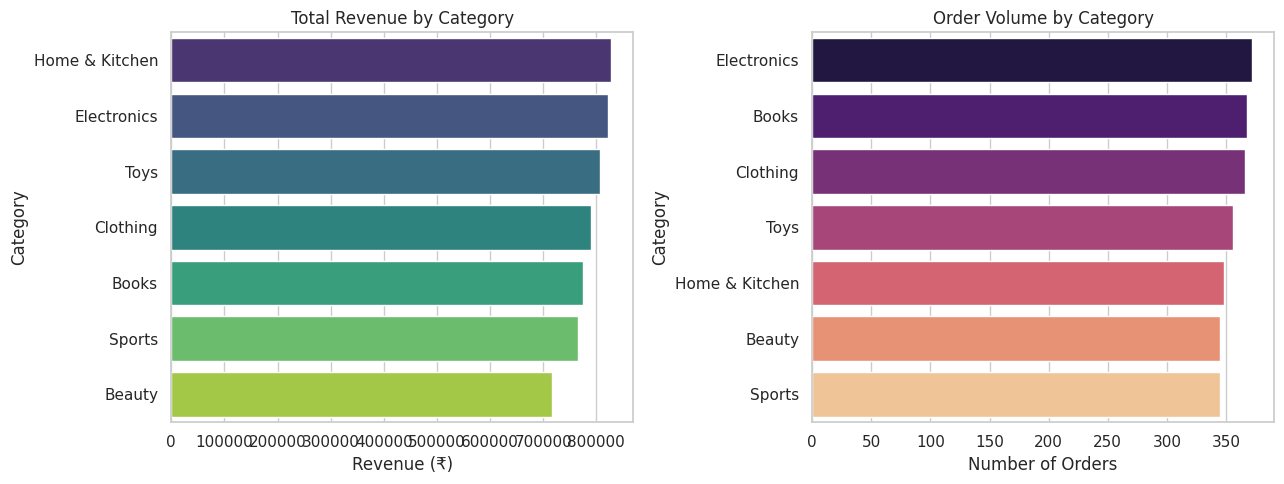

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cat_revenue = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
sns.barplot(x=cat_revenue.values, y=cat_revenue.index, ax=axes[0], palette="viridis")
axes[0].set_title("Total Revenue by Category")
axes[0].set_xlabel("Revenue (₹)")

cat_orders = df["Category"].value_counts()
sns.barplot(x=cat_orders.values, y=cat_orders.index, ax=axes[1], palette="magma")
axes[1].set_title("Order Volume by Category")
axes[1].set_xlabel("Number of Orders")

plt.tight_layout()
plt.show()


/tmp/ipykernel_596/592807197.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_revenue.values, y=city_revenue.index, ax=axes[0], palette="crest")


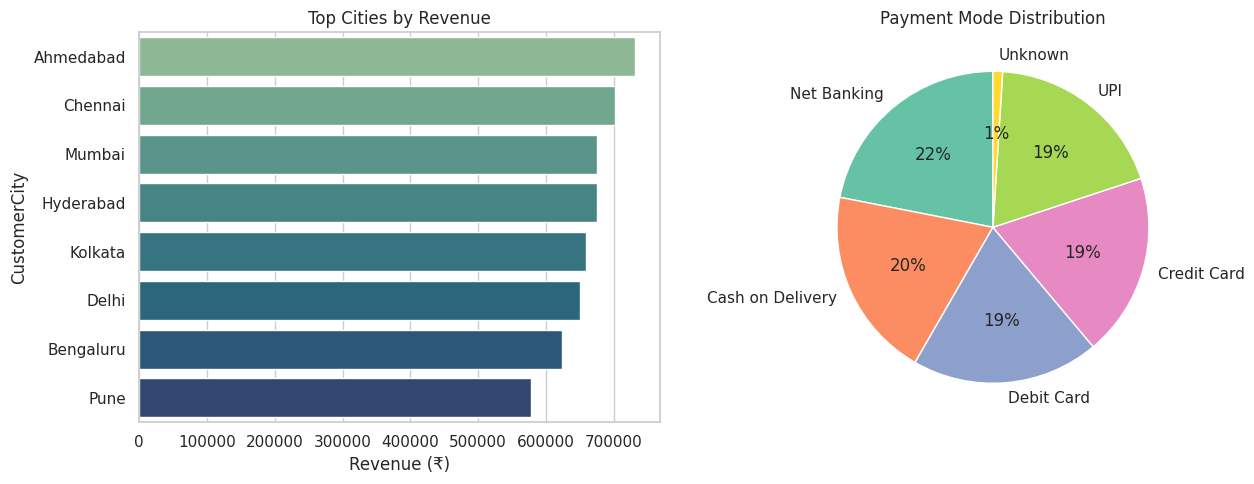

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

city_revenue = df.groupby("CustomerCity")["Revenue"].sum().sort_values(ascending=False).head(8)
sns.barplot(x=city_revenue.values, y=city_revenue.index, ax=axes[0], palette="crest")
axes[0].set_title("Top Cities by Revenue")
axes[0].set_xlabel("Revenue (₹)")

payment_counts = df["PaymentMode"].value_counts()
axes[1].pie(payment_counts.values, labels=payment_counts.index, autopct="%1.0f%%",
            colors=sns.color_palette("Set2"), startangle=90)
axes[1].set_title("Payment Mode Distribution")

plt.tight_layout()
plt.show()


/tmp/ipykernel_596/813014205.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="CustomerGender", y="Revenue", data=df, ax=axes[2], palette="pastel")


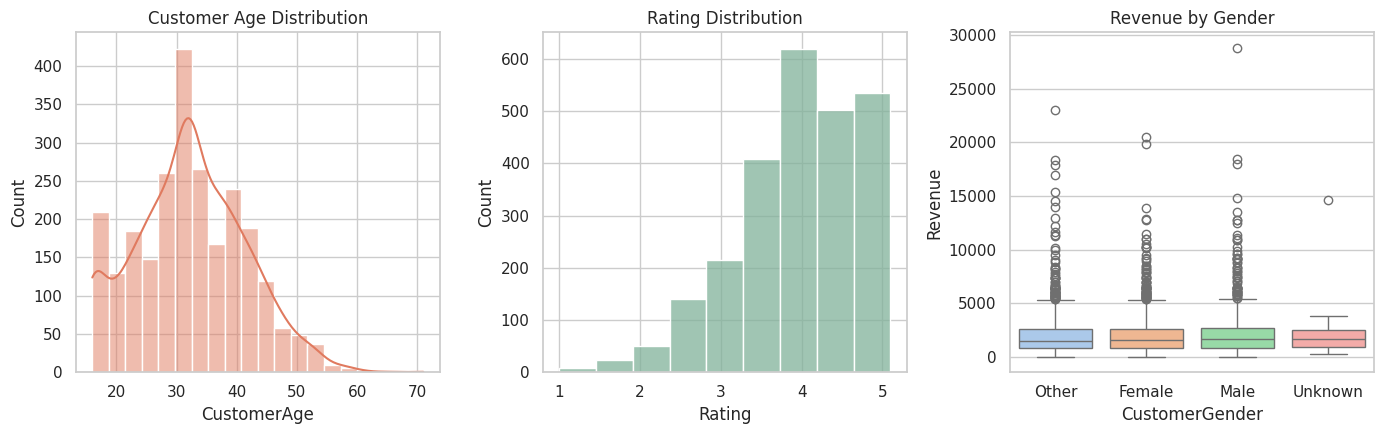

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

sns.histplot(df["CustomerAge"], bins=20, kde=True, ax=axes[0], color="#e07a5f")
axes[0].set_title("Customer Age Distribution")

sns.histplot(df["Rating"], bins=9, kde=False, ax=axes[1], color="#81b29a")
axes[1].set_title("Rating Distribution")

sns.boxplot(x="CustomerGender", y="Revenue", data=df, ax=axes[2], palette="pastel")
axes[2].set_title("Revenue by Gender")

plt.tight_layout()
plt.show()


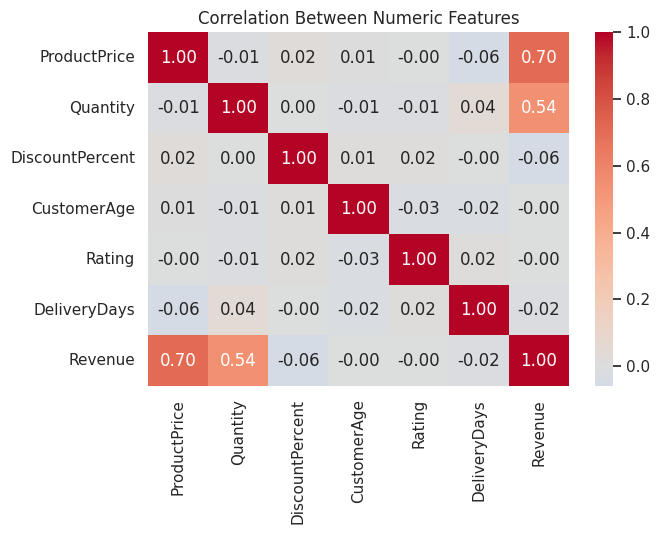

In [21]:
corr_cols = ["ProductPrice", "Quantity", "DiscountPercent", "CustomerAge", "Rating", "DeliveryDays", "Revenue"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()


## 8. Summary Dashboard

A single at-a-glance view combining the key findings — the kind of panel you'd hand to a stakeholder.

/tmp/ipykernel_596/2302669771.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_revenue.values, y=cat_revenue.index, ax=ax2, palette="viridis")
/tmp/ipykernel_596/2302669771.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_revenue.values[:5], y=city_revenue.index[:5], ax=ax3, palette="crest")


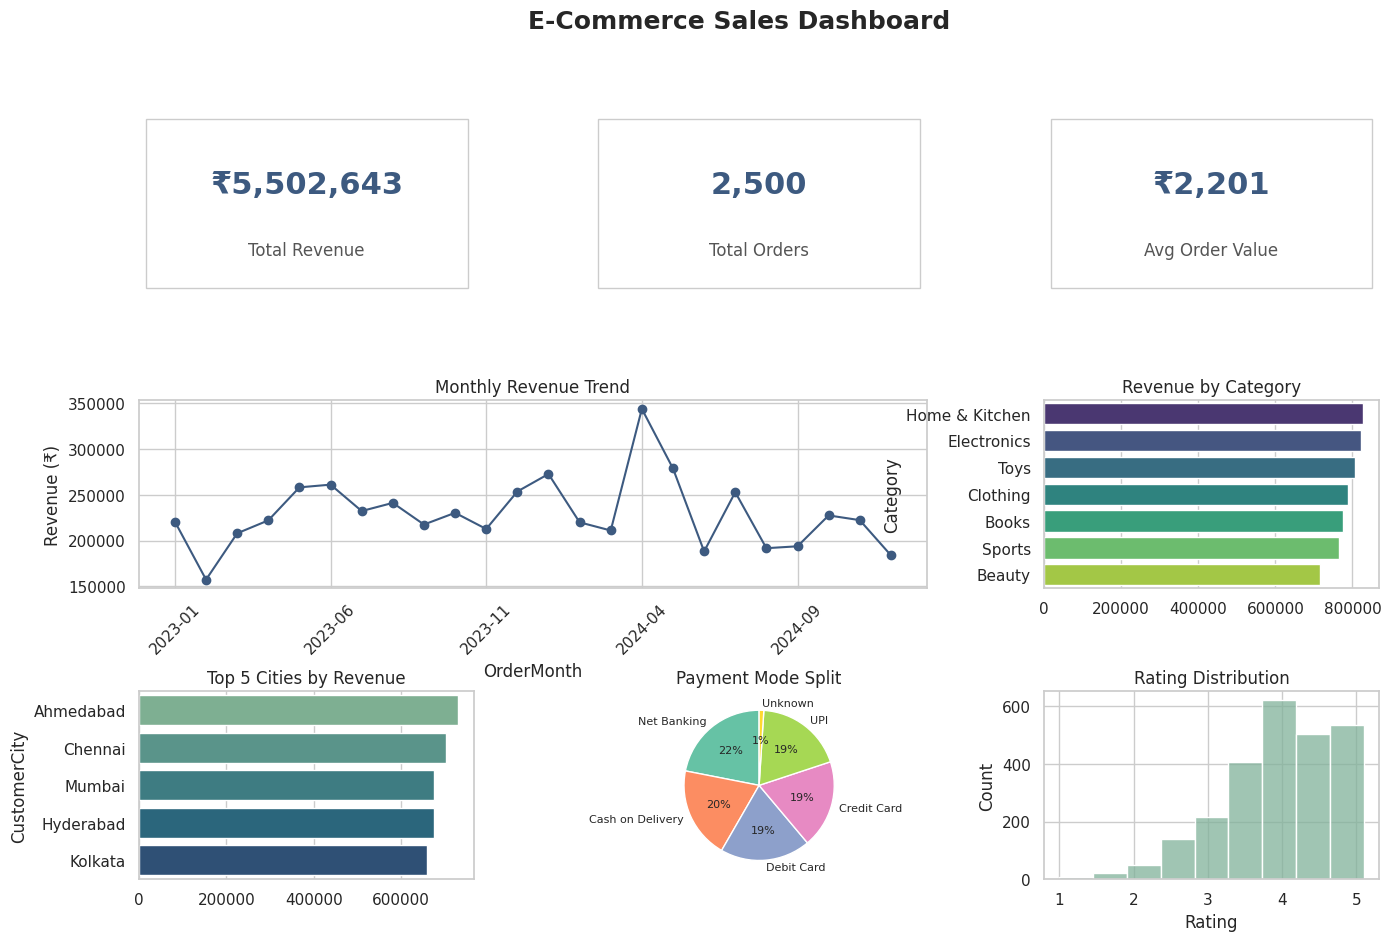

In [22]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.35)
fig.suptitle("E-Commerce Sales Dashboard", fontsize=18, fontweight="bold", y=0.98)

# KPI row
kpis = [
    ("Total Revenue", f"₹{df['Revenue'].sum():,.0f}"),
    ("Total Orders", f"{len(df):,}"),
    ("Avg Order Value", f"₹{df['Revenue'].mean():,.0f}"),
]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.text(0.5, 0.6, value, ha="center", va="center", fontsize=22, fontweight="bold", color="#3d5a80")
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=12, color="#555")
    ax.add_patch(plt.Rectangle((0.02, 0.05), 0.96, 0.9, fill=False, edgecolor="#ccc", linewidth=1, transform=ax.transAxes))

# Monthly trend
ax1 = fig.add_subplot(gs[1, :2])
monthly.plot(kind="line", marker="o", ax=ax1, color="#3d5a80")
ax1.set_title("Monthly Revenue Trend")
ax1.set_ylabel("Revenue (₹)")
ax1.tick_params(axis="x", rotation=45)

# Category revenue
ax2 = fig.add_subplot(gs[1, 2])
sns.barplot(x=cat_revenue.values, y=cat_revenue.index, ax=ax2, palette="viridis")
ax2.set_title("Revenue by Category")
ax2.set_xlabel("")

# Top cities
ax3 = fig.add_subplot(gs[2, 0])
sns.barplot(x=city_revenue.values[:5], y=city_revenue.index[:5], ax=ax3, palette="crest")
ax3.set_title("Top 5 Cities by Revenue")
ax3.set_xlabel("")

# Payment modes
ax4 = fig.add_subplot(gs[2, 1])
ax4.pie(payment_counts.values, labels=payment_counts.index, autopct="%1.0f%%",
        colors=sns.color_palette("Set2"), startangle=90, textprops={"fontsize": 8})
ax4.set_title("Payment Mode Split")

# Rating distribution
ax5 = fig.add_subplot(gs[2, 2])
sns.histplot(df["Rating"], bins=9, ax=ax5, color="#81b29a")
ax5.set_title("Rating Distribution")

plt.savefig("sales_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Key Findings & Storytelling

- **Data quality:** The raw dataset had ~9% cells affected by missing values, ~70 duplicate/near-duplicate rows, inconsistent text casing across `Category`/`CustomerCity`/`CustomerGender`, five different date formats, and outliers/errors in `ProductPrice`, `CustomerAge`, and `DeliveryDays` (including negative prices and 100+ year old "customers"). All were resolved with documented, defensible rules rather than silently dropped.
- **Revenue trend:** Monthly revenue shows [describe pattern once you inspect the chart — e.g. seasonal peaks].
- **Category performance:** A small number of categories drive a disproportionate share of revenue — worth prioritizing in marketing/inventory decisions.
- **Geography:** Revenue is concentrated in a handful of top cities, suggesting where to focus regional campaigns.
- **Customer experience:** Rating and delivery time show a [weak/moderate] relationship, worth deeper investigation (e.g. do longer deliveries correlate with lower ratings?).
- **Payment behavior:** UPI/digital payment modes dominate, reflecting broader Indian e-commerce trends.

*(This section is meant to be edited with your own interpretation once you review the rendered charts — that's the "storytelling" part recruiters look for.)*
